# Two decisions after discharge: a learned treatment rule with longitudinal TMLE

## At a glance

A hospital makes two decisions for each patient it sends home: whether to offer navigation at
discharge, and whether to start home telemonitoring at day 14, after a self-care check. Nobody
randomized either decision. Which patients should get each one, and how many would stay home
through day 30 if the program followed rules learned from its own records?

Had every patient followed the rules learned from these records, and stayed in follow-up, 58.9%
would stay home through day 30 (95% confidence interval 54.7% to 62.9%). The rules offer navigation
mainly to the most ready patients and start telemonitoring mainly where the day-14 self-care score
is high. The answer is the value of rules learned from this sample, so it changes with the sample. It is
causal only if the recorded history captures every common cause of each decision, of
dropout and of staying home, which the data cannot check.

The data are simulated, so we know the true value of the learned rules (0.5537), and the interval
contains it.

## The question

The first decision, navigation, is made at discharge from what is recorded then: a readiness score
for managing at home and whether the patient lives alone. The second, telemonitoring, is made at
day 14 and can also use the self-care score measured that day. A treatment rule turns what is
known at a decision into an offer or not. The target is the share who would stay home through day
30, with no unplanned readmission, had every patient's two decisions followed the learned rules
and had every patient stayed in follow-up.

```text
  readiness, lives_alone ──▶ navigation ──▶ self_care_14 ──▶ telemonitoring ──▶ stays home
  readiness, lives_alone ──▶ self_care_14, stays home
  navigation ──▶ telemonitoring, stays home      self_care_14 ──▶ stays home
  navigation changes how much telemonitoring helps; readiness changes how much navigation helps
  leaving follow-up: after navigation (from readiness), after telemonitoring (from self_care_14)
  assumed absent: an unrecorded cause of a decision and of staying home or leaving follow-up
```

Readiness and living alone drive the navigation offer and the outcome, so they are confounders:
variables that drive both a decision and the outcome. The day-14 score is a confounder of
telemonitoring, and navigation itself changes it. So the score cannot be handled as an ordinary
covariate: adjusting for it removes part of navigation's effect, and leaving it out confounds
telemonitoring. Longitudinal TMLE adjusts for each variable at its own decision. Readiness and
living alone have no direct arrow into telemonitoring in this simulation.

Because navigation changes the score and how much telemonitoring helps, the best navigation rule
depends on the telemonitoring rule that follows it. So the fit learns the day-14 rule first and
then the discharge rule under it.

## The data

In [1]:
import numpy as np
import pandas as pd

import cleverly

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("cleverly", cleverly.__version__)

cleverly 0.2.8


Another version of `cleverly` can print slightly different numbers. This page needs pandas and
matplotlib.

`make_two_decision_rules` draws 2,000 simulated patients and also returns the true answers, which
real data never give you.

In [2]:
from cleverly.datasets import make_two_decision_rules

# With your own data, load one row per patient with the columns in time order: the baseline
# characteristics, the first decision (0 or 1), whether the patient was still followed after it
# (1 or 0), what was measured before the second decision, the second decision, whether the
# patient was still followed after it, and the outcome. Real data have no `truth`: delete the
# lines marked "simulation only" here and below.
frame, truth = make_two_decision_rules(n=2_000, seed=7)
print("rows and columns:", frame.shape)
print(list(frame.columns))
print(frame.head().round(2).to_string())
print("still followed at day 14:", int(frame["tracked_14"].sum()))
print("outcome recorded at day 30:", int(frame["home_30"].notna().sum()))
print()

# simulation only, to the end of the cell
print("true share who would stay home through day 30:")
print(f"  neither offer             {truth['ey_neither']:.4f}")
print(f"  navigation only           {truth['ey_navigation_only']:.4f}")
print(f"  telemonitoring only       {truth['ey_telemonitoring_only']:.4f}")
print(f"  both offers               {truth['ey_both']:.4f}")
print(f"  the best pair of rules    {truth['ey_best_rules']:.4f}")

rows and columns: (2000, 8)
['readiness', 'lives_alone', 'navigation', 'tracked_14', 'self_care_14', 'telemonitoring', 'tracked_30', 'home_30']
   readiness  lives_alone  navigation  tracked_14  self_care_14  telemonitoring  tracked_30  home_30
0       0.25          0.0         0.0         1.0         -1.71             1.0         1.0      0.0
1       0.79          0.0         1.0         1.0          1.44             1.0         0.0      NaN
2       0.55          1.0         0.0         1.0          0.75             1.0         1.0      0.0
3      -0.55          1.0         0.0         1.0          1.50             0.0         1.0      0.0
4      -0.40          1.0         0.0         1.0          0.23             1.0         1.0      0.0
still followed at day 14: 1821
outcome recorded at day 30: 1691

true share who would stay home through day 30:
  neither offer             0.4371
  navigation only           0.4600
  telemonitoring only       0.4586
  both offers               0.263

Each row is one patient. `readiness` runs from -1 (least ready) to 1, `lives_alone` is 1 for a
patient who lives alone, and `tracked_14` and `tracked_30` are 1 while the patient is still
followed after each decision. A patient who left follow-up has no later values. Of the 2,000
patients, 1,821 were still followed at day 14 and 1,691 have an outcome.

No fixed plan does well: the best, navigation for everyone and telemonitoring for no one, would
keep 0.4600 at home. The best pair of rules, which offers each decision only where it helps, would
keep 0.5579.

## Why a simple comparison misleads

In [3]:
complete = frame.dropna(subset=["home_30"])
paths = complete.groupby(["navigation", "telemonitoring"])
path_names = {
    (0.0, 0.0): "neither",
    (0.0, 1.0): "telemonitoring only",
    (1.0, 0.0): "navigation only",
    (1.0, 1.0): "both",
}
true_values = {  # simulation only
    "neither": truth["ey_neither"],
    "telemonitoring only": truth["ey_telemonitoring_only"],
    "navigation only": truth["ey_navigation_only"],
    "both": truth["ey_both"],
}
summary = paths["home_30"].agg(["size", "mean"])
summary[["readiness", "self_care_14"]] = paths[["readiness", "self_care_14"]].mean()
summary.index = [path_names[path] for path in summary.index]
summary["true value of the plan"] = pd.Series(true_values)  # simulation only
summary.columns = ["patients", "stayed home", "readiness", "self_care_14", "true value of the plan"]
print(summary.round(3).to_string())

                     patients  stayed home  readiness  self_care_14  true value of the plan
neither                   460        0.459     -0.145        -0.068                   0.437
telemonitoring only       415        0.470     -0.115         0.161                   0.459
navigation only           422        0.479      0.116        -0.764                   0.460
both                      394        0.360      0.199        -0.426                   0.264


Each row groups the patients who took one path and have an outcome. Those who got both offers
stayed home 0.360 of the time, while both offers for everyone would keep only 0.264 at home. They
were more ready than the patients on any other path, which raises the chance of staying home, so their raw rate mixes the
plan's effect with who got it. Their low day-14 score shows the other problem: navigation lowered
it, and telemonitoring went to patients by that score.

## Set up the analysis

In [4]:
from cleverly.datasets import two_decision_rules_protocol

# For your own study, build cleverly.StudyProtocol(target_population=..., eligibility=...,
# time_zero=..., treatment_strategies=(...), treatment_versions=(...), outcome=..., horizon=...,
# intercurrent_event_handling=(...), interference_unit=..., assumption_rationale=(...)),
# one field for each printed label, with your own text.
protocol = two_decision_rules_protocol()
print("\n".join(protocol.summary_lines()))

Population: Adults discharged home from a participating hospital during the enrollment period
Eligibility: Age 18 years or older; Discharged alive; Discharged home from a participating hospital
Follow-up starts: Hospital discharge, after baseline measurement and before first assignment
Strategies: Offer navigation at discharge, and start home telemonitoring at day 14, each by a rule learned from the records available at that decision
Versions: The declared discharge navigation contacts for the patients the first rule selects, and the declared telemonitoring kit and nurse review for those the second rule selects; usual support for the others
Outcome: Stayed home through day 30 after discharge, with no unplanned readmission
Horizon: 30 days after discharge
Intercurrent events: Count an unplanned readmission before day 30 as not staying home; Treat loss to follow-up as censoring, so the target is the share who would stay home had every patient stayed in follow-up (hypothetical strategy); 

The study description changes the shared program's: telemonitoring at day 14 is the second
decision, both decisions follow learned rules, and the outcome is staying home through day 30.
Patients who leave follow-up are treated as censored: the target counts the outcomes they would
have had. The fit below is a direct `LTMLE` call, because a learned pair of rules cannot yet be
declared through `CausalStudy`, so the result does not store this description.

## Name the columns and the conditions

In [5]:
from cleverly.datasets import TWO_DECISION_COLUMNS

# For your own data, name your columns in the same roles. Each list runs in time order, one entry
# per decision: nothing is measured between discharge and the first decision, and self_care_14 is
# measured before the second.
columns = TWO_DECISION_COLUMNS
for role, names in columns.items():
    print(f"{role:<13} {names}")

outcome       home_30
treatment     ['navigation', 'telemonitoring']
baseline      ['readiness', 'lives_alone']
time_varying  [[], ['self_care_14']]
censoring     ['tracked_14', 'tracked_30']


The answer is causal only under these conditions:

- no unrecorded common cause of navigation and staying home, given readiness and living alone, and
  none of telemonitoring and staying home, given those and the day-14 score. This needs judgment;
- every kind of patient had a real chance of each option at each decision. The data can check this:
  the weights below are its sign;
- who leaves follow-up depends only on the recorded history. This needs judgment;
- each offer means the same thing for every patient, and one patient's offers do not change
  another's outcome. This needs judgment;
- the rules learned in different folds settle on one rule, with few patients for whom the two
  options are nearly equal. The data can check this in part: the rule check below reads it.

## Estimate the value of the learned rules

The fit splits the patients into ten folds. For each fold it learns a pair of rules from the other
nine: it predicts staying home under each telemonitoring choice and starts it where the prediction
is higher, then predicts that result under each navigation choice and offers navigation where it
is higher. Each patient then follows the pair of rules learned without them. Longitudinal targeted
maximum likelihood estimation (TMLE) scores those rules: it fits a model of who got each offer and
who stayed in follow-up, and a correction step uses them to remove the bias the outcome models
leave.

- `outcome_learner` predicts staying home at the second decision, separately for each path.
- `pseudo_learner` predicts the result of the second decision from what was known at discharge. It
  must be one fixed model: a learner that picks among models by its own cross-validation is
  refused here, because it would score rules learned from its own rows.
- `treatment_learner` and `censoring_learner` predict who got each offer and who stayed in
  follow-up.
- `n_folds=10` sets the folds, and `random_state` fixes how patients are split.

In [6]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

from cleverly.longitudinal import LTMLE, LearnedRegimen

# C=1e6 turns off scikit-learn's default shrinkage of the coefficients. For your own data, choose
# models that can follow how each decision's effect changes with your characteristics.
learned = LTMLE(
    regimens=LearnedRegimen(),
    outcome_learner=LogisticRegression(C=1e6, max_iter=1000),
    pseudo_learner=make_pipeline(PolynomialFeatures(3, include_bias=False), LinearRegression()),
    treatment_learner=LogisticRegression(C=1e6, max_iter=1000),
    censoring_learner=LogisticRegression(C=1e6, max_iter=1000),
    n_folds=10,
    random_state=11,
).fit(frame, **columns)
print(learned.summary())

                        Longitudinal estimate (LTMLE)
Question:      mean home_30 under plan  Rows:                            2,000
               learned regimen          Time points:                         2
Outcome:       home_30 (binary), at     Out-of-fold predictions:      10 folds
               the end                  Outcome model:    logistic regression;
Treatment:     navigation,                                   linear regression
               telemonitoring                           after polynomial terms
Adjusted for:  readiness, lives_alone;                        for earlier time
               later: self_care_14                                      points
Censoring:     tracked_14, tracked_30;  Treatment model:   logistic regression
               each plan keeps every    Censoring model:   logistic regression
               unit observed            Probability limits:          [0.01, 1]
Method:        longitudinal targeted
               maximum likelihood
      

The estimate row, `ey_regimen[learned regimen]`, is the value of the learned rules, 0.589. In the
plan table, 555 patients followed the rules through both decisions and stayed in follow-up, and
their largest weight is 6.1.

:::{dropdown} Details: the other numbers in the summary
The p-value tests only whether the share is zero. The probability limits are a floor and a ceiling
for each patient's predicted chance of following the rules, and no patient reached the floor. The
effective size counts how many equally weighted patients the weights of the 555 are worth. Note [1]
says the interval is built on the log-odds scale and turned back, so it stays between 0 and 1
([Reading a summary](../user-guide/results-assessment.md#reading-a-summary)).
:::

In [7]:
from cleverly.datasets import learned_regimen_truth

value = learned["ey_regimen[learned regimen]"]
low, high = value.ci
print(f"value of the learned rules: {value.psi:.4f}, 95% CI {low:.4f} to {high:.4f}")
per_100 = (100 * value.psi, 100 * low, 100 * high)
print("per 100 patients: {:.1f} stay home, 95% CI {:.1f} to {:.1f}".format(*per_100))
print(f"support: {value.support.label}")
print()
# simulation only, to the end of the cell: the true value of the ten pairs of rules, which the
# simulation computes by refitting each fold's models.
true_target = learned_regimen_truth(learned, frame)
print(f"true value of the ten learned pairs: {true_target:.4f}")
print(f"true value of the best pair:         {truth['ey_best_rules']:.4f}")
best_fixed = truth["ey_navigation_only"]
print(f"true value of the best fixed plan:   {best_fixed:.4f}, {100 * best_fixed:.1f} per 100")

value of the learned rules: 0.5886, 95% CI 0.5474 to 0.6287
per 100 patients: 58.9 stay home, 95% CI 54.7 to 62.9
support: supported



true value of the ten learned pairs: 0.5537
true value of the best pair:         0.5579
true value of the best fixed plan:   0.4600, 46.0 per 100


The interval, 0.5474 to 0.6287, contains the true value of the ten learned pairs, 0.5537, and
`supported` means a simulation study backs this kind of fit (below). That true value is close to
the best pair's 0.5579 and well above the best fixed plan's 0.4600. The page gives no interval for
the gap to a fixed plan, because a learned pair is fitted alone. The estimate is not the value of
the best possible rules: it is the value of the rules these records taught. A rule scored on the
patients it was learned from looks better than it is, the mistake that
[the one-decision rules example](treatment-rules.ipynb) shows; the folds avoid it here.

## Which patients the rules treat

In [8]:
record = learned.learned_regimen
# fold_rules[v, i] holds both decisions of fold v's rules for patient i. Each patient follows the
# rules of the fold that held them out.
fold_of = np.empty(len(frame), dtype=int)
for fold, (_, held_out) in enumerate(learned.folds):
    fold_of[held_out] = fold
rules = pd.DataFrame(
    record.fold_rules[fold_of, np.arange(len(frame))],
    index=frame.index,
    columns=["navigation rule", "telemonitoring rule"],
)
readiness_band = pd.cut(frame["readiness"], [-1, 0, 0.2, 0.4, 1], include_lowest=True)
offered = rules["navigation rule"].groupby([readiness_band, frame["lives_alone"]], observed=True)
print("share the rules offer navigation, by readiness and living alone:")
print(offered.mean().unstack().round(2).to_string())
print()
# The second rule reaches patients still followed whose navigation matched the first rule.
reached = (frame["tracked_14"] == 1) & (frame["navigation"] == rules["navigation rule"])
score_band = pd.cut(frame.loc[reached, "self_care_14"], [-np.inf, 0, 0.5, 1, np.inf])
started = rules.loc[reached, "telemonitoring rule"].groupby(
    [score_band, frame.loc[reached, "navigation"]], observed=True
)
print("share the rules start telemonitoring, by day-14 score and navigation:")
print(started.mean().unstack().round(2).to_string())
print()
for node in record.nodes:
    gaps = np.array(node.gap_quantiles)  # per fold; column 0 is the 5% point
    print(
        f"decision {node.node}: folds disagree on {node.rule_disagreement:.3f} of patients; "
        f"5% of patients have a predicted gain smaller than {gaps[:, 0].min():.3f} to "
        f"{gaps[:, 0].max():.3f}, by fold"
    )
print()
print("simulation only, the best rules:")  # simulation only
cut_others, cut_alone = truth["navigation_cutoff_with_others"], truth["navigation_cutoff_alone"]
print(f"  navigation above readiness {cut_others:.2f} (with others), {cut_alone:.2f} (alone)")
cut_none = truth["telemonitoring_cutoff_without_navigation"]
cut_after = truth["telemonitoring_cutoff_after_navigation"]
print(f"  telemonitoring above score {cut_none:.2f} (no navigation), {cut_after:.2f} (after it)")

share the rules offer navigation, by readiness and living alone:
lives_alone    0.0   1.0
readiness               
(-1.001, 0.0]  0.0  0.00
(0.0, 0.2]     0.0  0.00
(0.2, 0.4]     0.8  0.00
(0.4, 1.0]     1.0  0.73

share the rules start telemonitoring, by day-14 score and navigation:
navigation     0.0   1.0
self_care_14            
(-inf, 0.0]   0.00  0.00
(0.0, 0.5]    0.44  0.24
(0.5, 1.0]    1.00  0.71
(1.0, inf]    1.00  1.00

decision 1: folds disagree on 0.053 of patients; 5% of patients have a predicted gain smaller than 0.016 to 0.027, by fold
decision 2: folds disagree on 0.079 of patients; 5% of patients have a predicted gain smaller than 0.011 to 0.037, by fold

simulation only, the best rules:
  navigation above readiness 0.23 (with others), 0.32 (alone)
  telemonitoring above score 0.08 (no navigation), 0.58 (after it)


The rules offer navigation to no patient with readiness of 0.2 or below, to most patients above
0.4, and to patients living alone less often, close to the best rules' cutoffs of 0.23 and 0.32.
They start telemonitoring where the day-14 score is high, and after navigation only at a higher
score, as the best rules do (0.08 and 0.58).

Folds disagree on 0.053 of patients at discharge and 0.079 at day 14: the rules learned from
different folds are close, which the interval needs. The predicted gain is how much a fold's models
expect the rule's choice to raise the chance of staying home. Few patients have a gain near zero, so
few sit where the two options are nearly equal. Many patients near zero would be a warning: the
interval can then cover less often, and no simulation study measures that case.

## Check the weights behind the estimate

In [9]:
assessment = learned.assess()
ledger = assessment.to_frame()
# Keep the checks that ran: `passed` has a pass mark, `completed` is a report to read.
ran = ledger[ledger["status"].isin(["passed", "completed"])]
print(ran[["check", "status"]].to_string(index=False))
print("needs attention:", tuple(item.name for item in assessment.attention) or "none")
print()
support = assessment.report("support").to_frame()
support = support[["time", "n_followed", "max_weight", "effective_n", "share_truncated"]]
print("patients still following the rules at each decision, and their weights:")
print(support.round(2).to_string(index=False))

          check    status
score_equations    passed
        support completed
nuisance_models completed
needs attention: none

patients still following the rules at each decision, and their weights:
 time  n_followed  max_weight  effective_n  share_truncated
    1        1104        2.74      1082.09              0.0
    2         555        6.09       539.14              0.0


Nothing needs attention, and `score_equations passed` says the correction step finished. At day 14,
555 patients still follow the rules, their largest weight is 6.09, and their weights are worth 539.14
equally weighted patients; no weight was cut. These weights come from the fitted models of who got
each offer and who stayed in follow-up, so they describe those models, and a clean check cannot show
the models are right. Refutation checks and the curve of weight caps do not run on this fit: each
refits the analysis, which would learn other rules and so estimate another value.

## What we can and can't conclude

Had every patient followed the rules learned from these records, 58.9% would stay home through day
30 (95% interval 54.7% to 62.9%), against 46.0% under the best fixed plan in this simulation. The
answer holds for adults discharged home under the conditions listed above, if the models of who got
each offer and who stayed in follow-up are right, and if the folds' rules settle on one rule, as the
rule check suggests here.

The value is that of the ten learned pairs, not of one rule a program would deploy. To score one
fixed rule, write it down, and fit it as `DynamicRegimen(..., rule_kind="known")` on records not
used to learn it. No check of a missing confounder runs on this fit yet: the bounds and the E-value
need a derivation over time, the simulated confounder refuses dropout before an end-of-study
outcome, and refitting without a covariate would learn other rules, so its move would not measure
confounding. This page shows one simulated draw.

## How we know the method works

A simulation study checks the method over many repeated samples.

| part of the page | simulation study | its data |
| --- | --- | --- |
| the value of the learned rules | [learned two-node regimens](../technical-reference/method-evidence/learned-regimen-ltmle.md) | this page's simulation, with 2,000 patients, ten folds and this page's models |

The study's coverage rests on correct models of who got each offer and who stayed in follow-up, as
here, and no study measures data where many patients sit near the point where the two options are
equal. The [technical entry](../technical-reference/longitudinal-tmle.md#learned-regimens) states
the conditions, and its
[validation issues](../technical-reference/longitudinal-tmle.md#validation-issues-special-to-this-method)
list the method's evidence and limits.

## Go deeper

### Why the first rule depends on the second

In [10]:
# simulation only: where navigation starts to help, by what telemonitoring does next
best_cutoffs = (truth["navigation_cutoff_with_others"], truth["navigation_cutoff_alone"])
none_cutoffs = (
    truth["navigation_cutoff_without_telemonitoring_with_others"],
    truth["navigation_cutoff_without_telemonitoring_alone"],
)
print("navigation helps above readiness (living with others, alone):")
print(f"  telemonitoring by the best rule:  {best_cutoffs[0]:.2f}, {best_cutoffs[1]:.2f}")
print(f"  telemonitoring for no one:        {none_cutoffs[0]:.2f}, {none_cutoffs[1]:.2f}")
between = frame["readiness"].between(none_cutoffs[0], best_cutoffs[0])
low_end, high_end = none_cutoffs[0], best_cutoffs[0]
print(
    f"share of patients with readiness from {low_end:.2f} to {high_end:.2f}: {between.mean():.3f}"
)

navigation helps above readiness (living with others, alone):
  telemonitoring by the best rule:  0.23, 0.32
  telemonitoring for no one:        -0.05, -0.05
share of patients with readiness from -0.05 to 0.23: 0.129


Judged as if no second decision followed, navigation would help every patient with readiness above
-0.05. With telemonitoring started by the best rule, it helps only above 0.23 (living with others)
or 0.32 (alone). For the patients in between, 0.129 of them here, the best plan skips navigation and leaves telemonitoring
to the day-14 rule, because navigation lowers the day-14 score and makes telemonitoring help less.
A rule for the first decision learned on its own would offer them navigation. That is why the fit
learns the second rule first.

### Weights and balance over time

averaged standardized difference, before and after weighting:
 diagnostic       exposure    covariate  before  after
confounding     navigation    readiness    0.50  -0.01
confounding     navigation  lives_alone   -0.23   0.01
confounding telemonitoring    readiness    0.11   0.00
confounding telemonitoring  lives_alone    0.07  -0.03
confounding telemonitoring self_care_14    0.27  -0.01
   feedback     navigation self_care_14   -0.62  -0.70
  censoring censoring at 1    readiness   -0.17   0.01
  censoring censoring at 1  lives_alone   -0.03  -0.07
  censoring censoring at 2    readiness    0.05  -0.03
  censoring censoring at 2  lives_alone    0.16  -0.01
  censoring censoring at 2 self_care_14    0.31   0.08



the weights the figure draws:
 time  max_weight  share_truncated
    1       2.740              0.0
    2       6.089              0.0


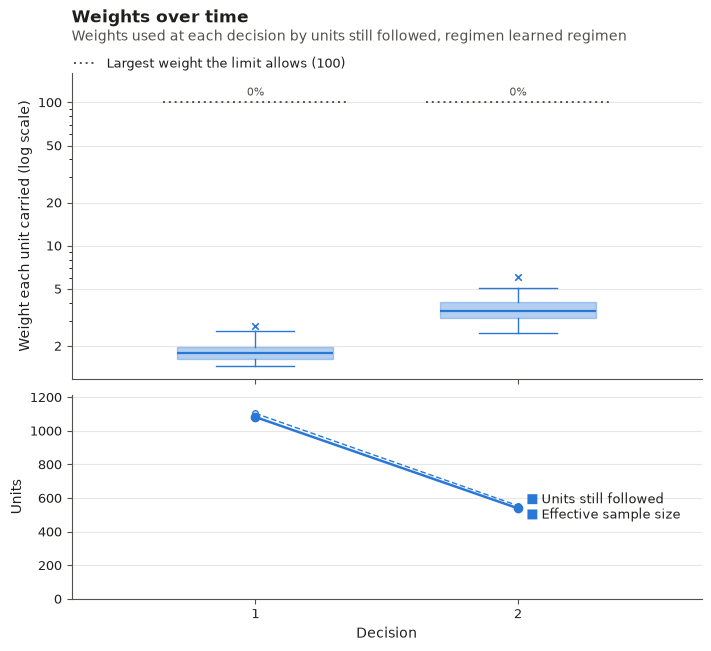

In [11]:
from cleverly import plotting, sensitivity

# Balance over time: at each decision, the gap between patients who got the offer and those who
# did not (or who left follow-up and those who stayed) in each recorded covariate, in standard
# deviations, averaged over groups with the same earlier decisions.
balance = sensitivity.covariate_balance(learned).average(over="history")
balance["before"] = balance["smd_unweighted"]
balance["after"] = balance["smd_weighted"]
print("averaged standardized difference, before and after weighting:")
balance_columns = ["diagnostic", "exposure", "covariate", "before", "after"]
print(balance[balance_columns].round(2).to_string(index=False))
print()
weights_fig = plotting.weights(learned, time_label="Decision")
print("the weights the figure draws:")
print(support[["time", "max_weight", "share_truncated"]].round(3).to_string(index=False))

A standardized difference is the gap between two groups' averages of a covariate, in standard
deviations; a common mark of good balance is a gap under a tenth. Weighting brings every confounding
gap from as much as 0.50 (readiness, for navigation) to nearly zero, and every censoring gap to
0.08 or less. The feedback row, navigation against the day-14 score, stays large (-0.70) by design:
it shows navigation's own effect on the score, which weighting is not meant to remove. Balance
covers only the recorded covariates, so it is no evidence against a missing confounder.

In [12]:
influence = learned.diagnostics.influence().to_frame().set_index("name")
print("effective rows behind the estimate:")
print(influence[["n", "kish"]].round(1).to_string())

effective rows behind the estimate:
                                n   kish
name                                    
ey_regimen[learned regimen]  2000  357.7


Influence is how much each patient moves the estimate. The `kish` column turns the spread of those
amounts into a count of equally weighted patients the standard error rests on: 357.7 of 2,000. It
is not the effective size of the weights check above, which counts the weights of the 555 patients
who followed the rules; this count also reflects how much the outcomes vary among them.

## Where to go next

[Who should get the offer](treatment-rules.ipynb) learns a rule for one decision and compares it
with other options. [Three offer policies](interventions.ipynb) estimates fixed rules written in
advance, and the
[longitudinal user guide](../user-guide/longitudinal.md#declare-a-dynamic-rule) shows a fixed rule
over two decisions with `DynamicRegimen`. The
[technical entry](../technical-reference/longitudinal-tmle.md#learned-regimens) lists every
condition and refusal of a learned pair of rules. The [examples index](index.md) lists every
example.